<a href="https://colab.research.google.com/github/ailab-nda/ML/blob/main/FSML/chap08_jp_eng_ans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 第8章 ニューラルネットワーク

多層ニューラルネットワークでの識別をKerasでコーディングします。

# Chapter 8 Neural Networks

We code multilayer neural network classification using Keras.

## 準備

必要なライブラリ等を読み込みます。

## Preparation

Load the required libraries.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

## データの読み込み

## Loading the Data

MNISTデータは手描き数字画像認識のためのデータセットです。学習用60000事例、評価用10000事例で、それぞれ28x28の行列で画像が表現されています。

The MNIST data is a dataset for handwritten digit image recognition. It has 60,000 training examples and 10,000 test examples, each image represented as a 28x28 matrix.

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
X_train.shape

(60000, 28, 28)

パターン行列からデータを1つ取り出して、pyplotで表示します。

Take one example from the pattern matrix and display it with pyplot.

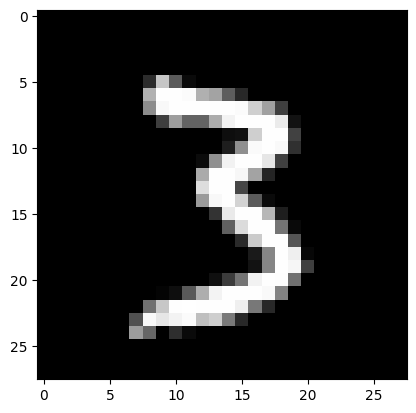

In [4]:
plt.gray()
plt.imshow(X_train[130])

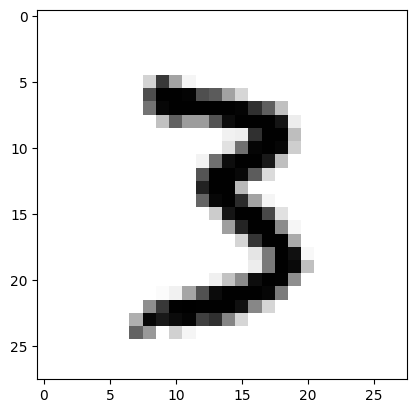

In [5]:
plt.imshow(255 - X_train[130])

正解ベクトルの最初の20要素程度を表示させて、どのようにデータが並んでいるのかを確認します。

Display roughly the first 20 elements of the label vector to see how the data is arranged.

In [6]:
y_train[0:20]

array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4, 3, 5, 3, 6, 1, 7, 2, 8, 6, 9],
      dtype=uint8)

入力値のとりうる範囲を0-255から0-1に変換します。

Convert the range of input values from 0-255 to 0-1.

In [7]:
X_train = X_train / 255.0
X_test = X_test / 255.0

正解をone-hotベクトルに変換します。

Convert the labels to one-hot vectors.

In [8]:
y_train = keras.utils.to_categorical(y_train)
y_test = keras.utils.to_categorical(y_test)

## ニューラルネットワークの構造と学習時のハイパーパラメータの設定

3層のフィードフォワード型ネットワークで学習します。

*   入力層は28x28の2次元画像を784次元の1次元ベクトルに変換 (Flatten)します
*   中間層は128個のユニットで、活性化関数はシグモイド関数です
*   出力層のユニット数はクラス数に合わせて10個で、活性化関数はすべての出力値の合計が1になるようにしたsoftmax関数です



## Setting the Network Structure and Training Hyperparameters

We train a 3-layer feedforward network.

*   The input layer converts the 28x28 two-dimensional image into a 784-dimensional one-dimensional vector (Flatten)
*   The hidden layer has 128 units with the sigmoid activation function
*   The output layer has 10 units to match the number of classes, with the softmax activation function, which makes all output values sum to 1



In [9]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(128, activation='sigmoid'),
    keras.layers.Dense(10,  activation='softmax')
])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

損失関数と最適化器を指定します。metricsは学習時に表示される数値で、学習が進んでいることを確認できるように設定します。

Specify the loss function and the optimizer. The metrics are values displayed during training, set so that you can confirm that training is progressing.

In [38]:
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['acc'])

ミニバッチのサイズと、繰り返し数を指定して学習を行います。

Specify the mini-batch size and the number of epochs, and train.

In [39]:
model.fit(X_train, y_train, batch_size=200, epochs=3)

Epoch 1/3
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - acc: 0.9485 - loss: 0.1850
Epoch 2/3
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9492 - loss: 0.1831
Epoch 3/3
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9495 - loss: 0.1820


評価用データで評価します。

Evaluate on the test data.

In [40]:
score = model.evaluate(X_test, y_test)
print(f"Accuracy: {score[1]:.2f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9440 - loss: 0.1985
Accuracy: 0.94


## 練習問題

活性化関数sigmoid、最適化器sgd（最急勾配法）で６階層ネットワークを構成し、勾配消失のために学習が進まないことを確認してください。次に、活性化関数を変更して、学習がうまくできることを確認してください。余力があれば、最適化器入れ替えの効果についても確認してください。


## Exercise

Build a 6-layer network with the sigmoid activation function and the sgd (steepest gradient descent) optimizer, and confirm that training does not progress because of vanishing gradients. Next, change the activation function and confirm that training succeeds. If time permits, also examine the effect of swapping the optimizer.


### 解答例


### Sample Solution


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

## データの読み込み

## Loading the Data

In [14]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

入力値のとりうる範囲を0-255から0-1に変換します。

Convert the range of input values from 0-255 to 0-1.

In [15]:
X_train = X_train / 255.0
X_test = X_test / 255.0

正解をone-hotベクトルに変換します。

Convert the labels to one-hot vectors.

In [16]:
y_train = tf.keras.utils.to_categorical(y_train)
y_test = tf.keras.utils.to_categorical(y_test)

## ニューラルネットワークの構造と学習時のハイパーパラメータの設定

6層のフィードフォワード型ネットワークで学習します。

## Setting the Network Structure and Training Hyperparameters

We train a 6-layer feedforward network.

In [17]:
af = 'sigmoid'
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(10,  activation='softmax')
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 151,306 (591.04 KB)

 Trainable params: 151,306 (591.04 KB)

 Non-trainable params: 0 (0.00 B)

損失関数と最適化器を指定します。metricsは学習時に表示される数値で、学習が進んでいることを確認できるように設定します。

Specify the loss function and the optimizer. The metrics are values displayed during training, set so that you can confirm that training is progressing.

In [18]:
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['acc'])

ミニバッチのサイズと、繰り返し数を指定して学習を行います。lossやaccがほとんど変化しないことを確認してください。

Specify the mini-batch size and the number of epochs, and train. Confirm that loss and acc hardly change.

In [19]:
model.fit(X_train, y_train, batch_size=200, epochs=5)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - acc: 0.1108 - loss: 2.3135
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.1128 - loss: 2.3010
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.1123 - loss: 2.3008
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.1125 - loss: 2.3008
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.1130 - loss: 2.3006


評価用データで評価します。

Evaluate on the test data.

In [20]:
score = model.evaluate(X_test, y_test)
print(f"Accuracy: {score[1]:.2}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - acc: 0.1135 - loss: 2.3003
Accuracy: 0.11


10クラス問題で正解率が10%程度なので、まったく学習ができていないことがわかります。

Since the accuracy is about 10% on a 10-class problem, you can see that no learning has taken place at all.

活性化関数を変更します。学習が進んでいる様子を確認してください。

Change the activation function. Confirm that training is progressing.

In [21]:
af = 'relu'

model2 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(10,  activation='softmax')
])

In [22]:
model2.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['acc'])

In [23]:
model2.fit(X_train, y_train, batch_size=200, epochs=5)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - acc: 0.4970 - loss: 1.8536
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - acc: 0.8248 - loss: 0.6748
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.8759 - loss: 0.4357
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.8953 - loss: 0.3642
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9052 - loss: 0.3255


In [24]:
score = model2.evaluate(X_test, y_test)
print(f"Accuracy: {score[1]:.2}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9092 - loss: 0.3019
Accuracy: 0.91


もとのネットワークで、最適化器のみ変更してみます。

Change only the optimizer in the original network.

In [25]:
af = 'sigmoid'
model3 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(10,  activation='softmax')
])

In [26]:
model3.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['acc'])

In [27]:
model3.fit(X_train, y_train, batch_size=200, epochs=5)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - acc: 0.6339 - loss: 1.1854
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9066 - loss: 0.3414
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9357 - loss: 0.2297
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9510 - loss: 0.1741
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9596 - loss: 0.1395


In [28]:
score = model3.evaluate(X_test, y_test)
print(f"Accuracy: {score[1]:.2}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9586 - loss: 0.1457
Accuracy: 0.96


活性化関数と最適化器の両方を変えてみます。

Change both the activation function and the optimizer.

In [29]:
af = 'relu'

model4 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(128, activation=af),
    tf.keras.layers.Dense(10,  activation='softmax')
])

In [30]:
model4.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['acc'])

In [31]:
model4.fit(X_train, y_train, batch_size=200, epochs=5)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - acc: 0.8959 - loss: 0.3509
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9628 - loss: 0.1248
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9733 - loss: 0.0870
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9787 - loss: 0.0684
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9821 - loss: 0.0557


In [32]:
score = model4.evaluate(X_test, y_test)
print(f"Accuracy: {score[1]:.2}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.9746 - loss: 0.0850
Accuracy: 0.97


適切に設定を行うと、学習効率が上がることがわかります。

Training efficiency improves when the settings are chosen appropriately.